# FlappyBird DQN trên Google Colab: huấn luyện và đánh giá

Notebook này gộp sáu notebook `01_environment` đến `06_evaluate` thành **một file duy nhất** để chạy trên Google Colab. Agent học chơi `flappy-bird-gymnasium` bằng DQN kết hợp Double DQN và Dueling Network, theo đặc tả trong `Problem_Definition.md` và `Implementation_Notes.md`.

## Cách dùng

1. Mở notebook trên Colab. Chọn **Runtime → Change runtime type → CPU**. Mạng chỉ có khoảng 70 nghìn tham số và batch 64, nên GPU không làm nhanh hơn đáng kể.
2. Chọn **Runtime → Run all**. Colab sẽ hỏi quyền truy cập Google Drive; đồng ý để checkpoint được lưu lên Drive.
3. Nếu phiên Colab bị ngắt giữa chừng, mở lại notebook và **Run all** lần nữa. Huấn luyện tự chạy tiếp từ lần lưu gần nhất, không phải bắt đầu lại từ khung hình 0.
4. Chỉ muốn đánh giá một agent đã huấn luyện: chạy các mục 1 đến 9, bỏ qua mục 10 và 11, rồi chạy mục 12 trở đi.

## Nội dung

| Mục | Nội dung |
|---|---|
| 1 | Cài thư viện |
| 2 | Cấu hình |
| 3 | Thư mục lưu trên Google Drive |
| 4 | Import |
| 5 | Môi trường `FlappyEnv` |
| 6 | Q-Network với đầu ra Dueling |
| 7 | Experience Replay |
| 8 | Agent DQN |
| 9 | Lưu và khôi phục trạng thái huấn luyện |
| 10 | Kiểm tra nhanh các thành phần |
| 11 | Huấn luyện |
| 12 | Đường học |
| 13 | Đánh giá cuối |
| 14 | Kiểm tra giá trị Q |
| 15 | Xem agent chơi (video) |

## Khác biệt so với sáu notebook cũ

Các thay đổi này xử lý những vấn đề ghi trong `logs/1.txt`:

- **Không còn `%run`** giữa các notebook (mục 2 của log). Mọi thành phần nằm trong cùng một file, mỗi thành phần một cell, và phần kiểm tra chỉ chạy một lần ở mục 10.
- **Chạy tiếp được sau khi bị ngắt** (mục 4 của log). Ở mỗi lần đánh giá, notebook lưu toàn bộ trạng thái huấn luyện lên Drive: trọng số hai mạng, trạng thái Adam, Experience Replay, bộ đếm khung hình và trạng thái bộ sinh số ngẫu nhiên. Ngoài `best.weights.h5` và `last.weights.h5`, mỗi lần đánh giá còn lưu một bản trọng số riêng trong `snapshots/`.
- **Ghi log liên tục** (mục 4 của log). Mỗi lần đánh giá ghi thêm một dòng vào `history.jsonl` ngay lập tức, nên số liệu không mất khi tiến trình bị dừng đột ngột.
- **Cấu hình tập trung** (mục 5 của log). Mọi tham số của huấn luyện và đánh giá nằm trong một cell ở mục 2.
- **Thăm dò lệch về IDLE** (mục 7 của log). Khi chọn hành động ngẫu nhiên, FLAP chỉ được chọn với xác suất 0,1 thay vì 0,5 (mục 5 của `Implementation_Notes.md`).

Thuật toán, kiến trúc mạng và các siêu tham số khác giữ nguyên như `05_train`.

## 1. Cài thư viện

Colab đã có sẵn TensorFlow, Keras 3, NumPy và Matplotlib. Cell này chỉ cài thêm hai gói của trò chơi, đúng phiên bản dự án đã ghim trong `requirements.txt`:

- `gymnasium==1.3.0`
- `flappy-bird-gymnasium==0.4.0` (kéo theo `pygame`)

Khi chạy ngoài Colab (ví dụ trong conda env `flappybird` trên máy), cell không cài gì, vì môi trường đó đã có đủ gói.

In [27]:
import sys
import subprocess

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "gymnasium==1.3.0", "flappy-bird-gymnasium==0.4.0"], check=True)
print("Đang chạy trên Colab:", IN_COLAB)

Đang chạy trên Colab: True


## 2. Cấu hình

Đây là nơi **duy nhất** cần sửa khi muốn đổi tham số. Các giá trị lấy từ mục 5 của `Implementation_Notes.md`. Chúng được chọn bằng lập luận và **chưa được kiểm chứng bằng huấn luyện**.

**Huấn luyện (`CONFIG`)**

| Tham số | Giá trị | Ghi chú |
|---|---|---|
| `run_name` | `"dqn_run1"` | Tên thư mục của lần chạy trên Drive. Đổi tên để bắt đầu một lần chạy mới |
| `resume` | `True` | Nếu thư mục đã có trạng thái lưu thì chạy tiếp từ đó |
| `total_frames` | 1.000.000 | Mức tối thiểu để giá trị lan đủ xa với γ = 0,99. Có thể tăng rồi chạy lại để huấn luyện thêm |
| `gamma` | 0,99 | |
| `learning_rate` | 0,0001 | Adam |
| `hidden_units` | 256 | Số nơ-ron mỗi lớp ẩn |
| `buffer_capacity` | 100.000 | |
| `learning_starts` | 10.000 | Bắt đầu học khi Experience Replay có đủ chừng này transition |
| `batch_size` | 64 | |
| `update_every` | 4 | Cập nhật mạng mỗi 4 khung hình |
| `target_sync_every` | 1.000 | Tính theo **số lần cập nhật**, tức 4.000 khung hình |
| ε | 1,0 về 0,01 trong 100.000 khung hình | |
| `random_flap_prob` | 0,1 | Xác suất chọn FLAP khi hành động ngẫu nhiên. 0,5 nghĩa là ngẫu nhiên đều |
| Đánh giá định kỳ | Mỗi 25.000 khung hình, 20 ván, `score_limit` 200 | Môi trường riêng, seed cố định khác seed huấn luyện. Trạng thái huấn luyện cũng được lưu ở mỗi lần này |

**Vì sao `random_flap_prob` là 0,1.** Với P(FLAP) = 0,5, chim vỗ cánh quá nhiều và đâm vào ống trên của ống đầu tiên trong 100% số ván, nên 10.000 transition đầu tiên trong Experience Replay không có lần nào nhận reward +1. Với 0,1, khoảng 6,3% số ván ngẫu nhiên vượt được ống đầu tiên. Vì Q-Learning là off-policy, Target không cần thay đổi.

**Đánh giá cuối (`EVAL_CONFIG`)**: 100 ván với ε = 0, mỗi ván dừng ở 1.000 ống. `eval_seed` giống seed đánh giá định kỳ để các con số so sánh được với nhau.

In [28]:
CONFIG = dict(
    run_name="dqn_run1",
    resume=True,
    total_frames=1_000_000,
    gamma=0.99,
    learning_rate=1e-4,
    hidden_units=256,
    buffer_capacity=100_000,
    learning_starts=10_000,
    batch_size=64,
    update_every=4,
    target_sync_every=1_000,
    epsilon_start=1.0,
    epsilon_end=0.01,
    epsilon_decay_frames=100_000,
    random_flap_prob=0.1,
    eval_every=25_000,
    eval_episodes=20,
    eval_score_limit=200,
    train_seed=0,
    eval_seed=12345,
)

EVAL_CONFIG = dict(
    checkpoint_name="best.weights.h5",
    n_episodes=100,
    score_limit=1_000,
    eval_seed=CONFIG["eval_seed"],
    q_check_score_limit=50,
    video_score_limit=20,
)

## 3. Thư mục lưu trên Google Drive

Máy ảo Colab bị xóa sạch khi phiên kết thúc, nên mọi thứ cần giữ lại được ghi lên Google Drive, trong thư mục `MyDrive/FlappyBird/<run_name>/`:

| File hoặc thư mục | Nội dung |
|---|---|
| `best.weights.h5` | Trọng số có điểm đánh giá trung bình cao nhất |
| `last.weights.h5` | Trọng số lúc huấn luyện dừng |
| `snapshots/frame_XXXXXXX.weights.h5` | Trọng số tại mỗi lần đánh giá, dùng để so sánh hoặc quay lại khi agent bị suy giảm |
| `history.jsonl` | Mỗi dòng là kết quả một lần đánh giá |
| `state/` | Trạng thái để chạy tiếp: hai mạng, Adam, Experience Replay (khoảng 10 MB), bộ đếm |
| `agent_play.mp4` | Video ở mục 15 |

Khi chạy ngoài Colab, thư mục này nằm ở `colab_runs/<run_name>/` cạnh notebook.

In [29]:
import os

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/FlappyBird"
else:
    PROJECT_DIR = os.path.abspath("colab_runs")

RUN_DIR = os.path.join(PROJECT_DIR, CONFIG["run_name"])
os.makedirs(RUN_DIR, exist_ok=True)
print("Thư mục lưu:", RUN_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thư mục lưu: /content/drive/MyDrive/FlappyBird/dqn_run1
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thư mục lưu: /content/drive/MyDrive/FlappyBird/dqn_run1


## 4. Import

Colab không có màn hình, nên đặt `SDL_VIDEODRIVER=dummy` **trước khi** `pygame` được nạp. Nhờ vậy `pygame` vẫn vẽ được khung hình vào bộ nhớ để quay video ở mục 15.

`gymnasium` không được import ở đây mà chỉ ở cell của môi trường (mục 5), để các thành phần còn lại không phụ thuộc vào trò chơi.

In [14]:
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")  # pygame không cần màn hình

import json
import shutil
import time
import tempfile

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| NumPy", np.__version__)

TensorFlow 2.21.0 | Keras 3.13.2 | NumPy 2.4.6
TensorFlow 2.21.0 | Keras 3.13.2 | NumPy 2.4.6


## 5. Môi trường `FlappyEnv`

Đây là cell duy nhất import `gymnasium`. Các thành phần còn lại (Q-Network, Experience Replay, agent) chỉ làm việc với mảng số, nên kiểm thử được bằng dữ liệu giả.

**Hằng số.** Observation gồm 12 số đã chia tỉ lệ về khoảng −1 đến 1 (mục 2 của `Implementation_Notes.md`). Hai hành động: `IDLE = 0` (không làm gì) và `FLAP = 1` (vỗ cánh).

**Lớp `FlappyEnv`** xử lý ba điểm dễ sai của thư viện:

- Mặc định thư viện dùng chế độ LIDAR (180 tia), nên phải tạo môi trường với `use_lidar=False`.
- Observation trả về kiểu `float64`; lớp đổi sang `float32` trước khi đưa cho mạng.
- Sau khi chim va chạm (`terminated`), thư viện vẫn cho gọi `step()` và chạy tiếp với con chim đã chết. Lớp này báo lỗi nếu gọi `step()` khi ván đã kết thúc, để các transition sai không lọt vào Experience Replay.

`step()` trả về `(obs, reward, terminated, truncated, score)`. `truncated` chỉ là `True` khi đặt `score_limit` và điểm đạt giới hạn; lúc đó chim chưa chết. `score` là số ống đã vượt, chỉ dùng để chấm điểm, không phải một phần của trạng thái.

Khi huấn luyện, để `render_mode=None`. Trên Colab không mở được cửa sổ `"human"`, nên mục 15 dùng `render_mode="rgb_array"` để lấy từng khung hình dưới dạng ảnh.

**Chấm điểm một policy.** `play_episodes` cho một policy bất kỳ (hàm nhận observation, trả về hành động) chơi nhiều ván và trả về số ống vượt được mỗi ván.

- Seed chỉ đặt ở ván đầu, nên cùng seed cho cùng chuỗi ván và các lần đánh giá so sánh được với nhau.
- `score_limit` là bắt buộc: một agent giỏi có thể chơi mãi, và giới hạn này bảo đảm hàm luôn kết thúc.

`summarize_scores` tính trung bình, trung vị, thấp nhất và cao nhất, vì điểm dao động rất mạnh giữa các ván.

In [15]:
import gymnasium
import flappy_bird_gymnasium  # noqa: F401  (đăng ký "FlappyBird-v0" với gymnasium)

ENV_ID = "FlappyBird-v0"
OBS_DIM = 12
N_ACTIONS = 2
IDLE, FLAP = 0, 1


class FlappyEnv:
    # Bọc FlappyBird-v0: observation float32, chặn step() sau khi ván đã kết thúc.

    def __init__(self, score_limit=None, render_mode=None):
        self._env = gymnasium.make(ENV_ID, use_lidar=False,
                                   score_limit=score_limit, render_mode=render_mode)
        self._episode_over = True

    def reset(self, seed=None):
        obs, _ = self._env.reset(seed=seed)
        self._episode_over = False
        return obs.astype(np.float32)

    def step(self, action):
        if self._episode_over:
            raise RuntimeError("Ván đã kết thúc: phải gọi reset() trước khi gọi step().")
        obs, reward, terminated, truncated, info = self._env.step(int(action))
        self._episode_over = terminated or truncated
        return obs.astype(np.float32), float(reward), bool(terminated), bool(truncated), info["score"]

    def render(self):
        return self._env.render()

    def close(self):
        self._env.close()


def play_episodes(policy, n_episodes, seed, score_limit):
    # Chơi n_episodes ván với policy(obs) -> action, trả về mảng số ống vượt được mỗi ván.
    env = FlappyEnv(score_limit=score_limit)
    scores = []
    try:
        for episode in range(n_episodes):
            obs = env.reset(seed=seed if episode == 0 else None)
            episode_over = False
            while not episode_over:
                obs, _, terminated, truncated, score = env.step(policy(obs))
                episode_over = terminated or truncated
            scores.append(score)
    finally:
        env.close()
    return np.array(scores)


def summarize_scores(scores):
    return {
        "mean": float(np.mean(scores)),
        "median": float(np.median(scores)),
        "min": int(np.min(scores)),
        "max": int(np.max(scores)),
    }

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


## 6. Q-Network với đầu ra Dueling

Q-Network nhận 12 số của observation và trả về hai giá trị Q(s, IDLE) và Q(s, FLAP). MLP gồm hai lớp ẩn 256 nơ-ron dùng ReLU, sau đó chia thành hai nhánh:

```
h      = ReLU(W₂ · ReLU(W₁ · s))
V(s)   = w_V · h                         phần chung cho mọi hành động
A(s,a) = W_A · h                         phần chênh lệch giữa các hành động
Q(s,a) = V(s) + A(s,a) − (trung bình theo a' của A(s,a'))
```

Phép trừ trung bình làm V và A được xác định duy nhất: nếu không có nó, cộng c vào V và trừ c khỏi A vẫn cho cùng một Q. Mạng có 69.891 tham số.

Checkpoint chỉ lưu trọng số (`.weights.h5`); khi tải, mạng được dựng lại bằng hàm này.

In [16]:
def build_q_network(obs_dim=OBS_DIM, n_actions=N_ACTIONS, hidden_units=256):
    states = keras.Input(shape=(obs_dim,), name="state")
    h = keras.layers.Dense(hidden_units, activation="relu", name="hidden_1")(states)
    h = keras.layers.Dense(hidden_units, activation="relu", name="hidden_2")(h)
    value = keras.layers.Dense(1, name="value")(h)
    advantage = keras.layers.Dense(n_actions, name="advantage")(h)
    q_values = value + advantage - keras.ops.mean(advantage, axis=1, keepdims=True)
    return keras.Model(states, q_values, name="dueling_q_network")

## 7. Experience Replay

Hai khung hình liền nhau gần như giống nhau. Nếu mạng học theo đúng thứ tự chơi, nó sẽ khớp đoạn đang chơi và quên các đoạn trước. Experience Replay lưu nhiều transition gần đây và mỗi lần học lấy ngẫu nhiên một batch trong đó. Cách này dùng được vì Q-Learning là off-policy.

Mỗi transition gồm `(s, a, r, s', terminated)`. Cờ `terminated` cho biết chim đã va chạm, khi đó Target chỉ bằng reward. Bước bị cắt vì `score_limit` (`truncated`) được lưu với `terminated = False`, vì chim chưa chết.

- Bộ nhớ được cấp sẵn bằng các mảng numpy kích thước cố định. Khi đầy, transition mới ghi đè transition cũ nhất (bộ đệm vòng).
- Với sức chứa 100.000 transition, các mảng `float32` chiếm khoảng 11 MB.
- `sample()` lấy ngẫu nhiên có hoàn lại; với 100.000 phần tử và batch 64, việc trùng mẫu trong cùng batch rất hiếm.

**Mới so với `03_replay_buffer`:** `save()` và `load()` ghi và đọc toàn bộ nội dung bộ đệm, vị trí ghi tiếp theo và trạng thái bộ sinh số ngẫu nhiên vào một file `.npz`. Nhờ vậy khi chạy tiếp, agent không phải thu thập lại 10.000 transition từ đầu.

In [17]:
class ReplayBuffer:
    _ARRAYS = ("_states", "_actions", "_rewards", "_next_states", "_terminated")

    def __init__(self, capacity, obs_dim=OBS_DIM, seed=None):
        self.capacity = capacity
        self._states = np.zeros((capacity, obs_dim), dtype=np.float32)
        self._actions = np.zeros(capacity, dtype=np.int32)
        self._rewards = np.zeros(capacity, dtype=np.float32)
        self._next_states = np.zeros((capacity, obs_dim), dtype=np.float32)
        self._terminated = np.zeros(capacity, dtype=np.float32)
        self._next_index = 0
        self._size = 0
        self._rng = np.random.default_rng(seed)

    def __len__(self):
        return self._size

    def add(self, state, action, reward, next_state, terminated):
        i = self._next_index
        self._states[i] = state
        self._actions[i] = action
        self._rewards[i] = reward
        self._next_states[i] = next_state
        self._terminated[i] = float(terminated)
        self._next_index = (i + 1) % self.capacity
        self._size = min(self._size + 1, self.capacity)

    def sample(self, batch_size):
        if batch_size > self._size:
            raise ValueError(f"Cần ít nhất {batch_size} transition, mới có {self._size}.")
        idx = self._rng.integers(0, self._size, size=batch_size)
        return (self._states[idx], self._actions[idx], self._rewards[idx],
                self._next_states[idx], self._terminated[idx])

    def save(self, path):
        np.savez(path, next_index=self._next_index, size=self._size,
                 rng=json.dumps(self._rng.bit_generator.state),
                 **{name: getattr(self, name) for name in self._ARRAYS})

    def load(self, path):
        with np.load(path) as data:
            if data["_states"].shape != self._states.shape:
                raise ValueError(f"Bộ đệm đã lưu có kích thước {data['_states'].shape}, "
                                 f"khác cấu hình hiện tại {self._states.shape}.")
            for name in self._ARRAYS:
                getattr(self, name)[:] = data[name]
            self._next_index = int(data["next_index"])
            self._size = int(data["size"])
            self._rng.bit_generator.state = json.loads(str(data["rng"]))

## 8. Agent DQN

Agent ghép các phần của DQN: chọn hành động bằng ε-greedy, tính Target theo Double DQN, cập nhật Q-Network và đồng bộ Target Network. Agent chỉ làm việc với mảng số và không biết gì về trò chơi.

**Lịch giảm ε.** ε là xác suất chọn hành động ngẫu nhiên. ε giảm đều từ 1,0 (hoàn toàn ngẫu nhiên) về 0,01 trong 100.000 khung hình đầu, sau đó giữ nguyên.

**Hành động ngẫu nhiên lệch.** `random_action_probs` là xác suất của từng hành động khi agent chọn ngẫu nhiên. Mục 11 truyền `(0,9; 0,1)`, tức FLAP với xác suất 0,1. Để `None` thì chọn đều như cũ. Thay đổi này chỉ ảnh hưởng tới dữ liệu được thu thập; Target giữ nguyên vì Q-Learning là off-policy.

**Target theo Double DQN.** Mạng chính (trọng số w) chọn hành động tốt nhất ở s', còn Target Network (trọng số w⁻) chấm điểm hành động đó:

```
a*     = argmax_a' Q(s', a'; w)
Target = r                          nếu terminated
Target = r + γ · Q(s', a*; w⁻)      trong mọi trường hợp còn lại, kể cả truncated
```

Hai mạng có sai số khác nhau nên ít khi cùng lệch lên, nhờ đó giảm việc đánh giá Q quá cao. Target được tính ngoài `GradientTape`, nên được coi là hằng số khi lấy gradient.

**Cập nhật.** Loss là MSE, tức trung bình của (Target − Q(s, a; w))², tối ưu bằng Adam với learning rate 0,0001.

**Tốc độ.** Hàm cập nhật và hàm chọn hành động được bọc trong `tf.function`. Không dùng `model.predict` để chọn hành động từng khung hình, vì nó chậm hơn khoảng 150 lần (mục 6 của `Implementation_Notes.md`).

**Theo dõi.** `update()` trả về loss và trung bình max Q của batch. Khi agent chơi tốt, Q của các trạng thái an toàn nên tiến về khoảng 11,9 đến 12,9. Q vượt rõ 12,9 là dấu hiệu đánh giá quá cao hoặc việc học đang phân kỳ.

**Lưu và tải.**

- `save()` và `load()`: chỉ trọng số mạng chính (`.weights.h5`). Khi tải, Target Network được chép lại từ mạng chính. Dùng cho `best`, `last` và `snapshots`.
- `save_state()` và `load_state()` (mới): trọng số cả hai mạng, các biến của Adam (bộ đếm bước và hai trung bình trượt của gradient) và trạng thái bộ sinh số ngẫu nhiên. Dùng để chạy tiếp huấn luyện. Nếu chỉ tải trọng số mà bỏ trạng thái Adam, các bước cập nhật đầu tiên sau khi chạy tiếp sẽ có độ lớn sai.

In [18]:
def linear_epsilon(frame, start=1.0, end=0.01, decay_frames=100_000):
    fraction = min(frame / decay_frames, 1.0)
    return start + fraction * (end - start)


class DQNAgent:
    def __init__(self, obs_dim=OBS_DIM, n_actions=N_ACTIONS, gamma=0.99, learning_rate=1e-4,
                 hidden_units=256, random_action_probs=None, seed=None):
        self.n_actions = n_actions
        self.gamma = gamma
        self.random_action_probs = random_action_probs
        self.online = build_q_network(obs_dim, n_actions, hidden_units)
        self.target = build_q_network(obs_dim, n_actions, hidden_units)
        self.sync_target()
        self.optimizer = keras.optimizers.Adam(learning_rate)
        self._rng = np.random.default_rng(seed)

    # ---------- Chọn hành động ----------
    def act(self, state, epsilon):
        # ε-greedy: ngẫu nhiên (theo random_action_probs) với xác suất epsilon, ngược lại chọn Q lớn nhất.
        if self._rng.random() < epsilon:
            return int(self._rng.choice(self.n_actions, p=self.random_action_probs))
        return self.greedy_action(state)

    def greedy_action(self, state):
        state = np.asarray(state, dtype=np.float32)[None, :]
        return int(self._greedy(state).numpy()[0])

    @tf.function
    def _greedy(self, states):
        return tf.argmax(self.online(states, training=False), axis=1)

    def q_values(self, states):
        return self.online(np.asarray(states, dtype=np.float32), training=False).numpy()

    # ---------- Học ----------
    def update(self, states, actions, rewards, next_states, terminated):
        # Một bước Gradient Descent trên một batch. Trả về (loss, trung bình max Q).
        loss, mean_max_q = self._train_step(states, actions, rewards, next_states, terminated)
        return float(loss), float(mean_max_q)

    @tf.function
    def _train_step(self, states, actions, rewards, next_states, terminated):
        targets = self._double_dqn_targets(rewards, next_states, terminated)
        with tf.GradientTape() as tape:
            q_all = self.online(states, training=True)
            q_taken = tf.gather(q_all, actions, batch_dims=1)
            loss = tf.reduce_mean(tf.square(targets - q_taken))
        grads = tape.gradient(loss, self.online.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.online.trainable_variables))
        return loss, tf.reduce_mean(tf.reduce_max(q_all, axis=1))

    def _double_dqn_targets(self, rewards, next_states, terminated):
        best_actions = tf.argmax(self.online(next_states, training=False), axis=1)
        next_q = tf.gather(self.target(next_states, training=False), best_actions, batch_dims=1)
        return rewards + self.gamma * (1.0 - terminated) * next_q

    def sync_target(self):
        self.target.set_weights(self.online.get_weights())

    # ---------- Lưu và tải trọng số ----------
    def save(self, path):
        self.online.save_weights(path)

    def load(self, path):
        self.online.load_weights(path)
        self.sync_target()

    # ---------- Lưu và tải toàn bộ trạng thái (để chạy tiếp) ----------
    def _built_optimizer_variables(self):
        if not self.optimizer.built:
            self.optimizer.build(self.online.trainable_variables)
        return self.optimizer.variables

    def save_state(self, directory):
        self.online.save_weights(os.path.join(directory, "online.weights.h5"))
        self.target.save_weights(os.path.join(directory, "target.weights.h5"))
        np.savez(os.path.join(directory, "agent.npz"),
                 *[v.numpy() for v in self._built_optimizer_variables()],
                 rng=json.dumps(self._rng.bit_generator.state))

    def load_state(self, directory):
        self.online.load_weights(os.path.join(directory, "online.weights.h5"))
        self.target.load_weights(os.path.join(directory, "target.weights.h5"))
        variables = self._built_optimizer_variables()
        with np.load(os.path.join(directory, "agent.npz")) as data:
            n_saved = len(data.files) - 1  # trừ khóa "rng"
            if n_saved != len(variables):
                raise ValueError(f"File lưu có {n_saved} biến optimizer, cần {len(variables)}.")
            for i, variable in enumerate(variables):
                variable.assign(data[f"arr_{i}"])
            self._rng.bit_generator.state = json.loads(str(data["rng"]))

## 9. Lưu và khôi phục trạng thái huấn luyện

Colab có thể ngắt phiên bất cứ lúc nào (để máy rảnh quá lâu, hết thời lượng, mất mạng). Phần này cho phép chạy lại notebook và huấn luyện tiếp từ lần lưu gần nhất.

**Trạng thái gồm:**

- `online.weights.h5`, `target.weights.h5`, `agent.npz`: hai mạng, biến của Adam, bộ sinh số ngẫu nhiên của agent.
- `buffer.npz`: toàn bộ Experience Replay.
- `progress.json`: số khung hình, số lần cập nhật, số ván đã chơi và điểm đánh giá tốt nhất.

**Ghi an toàn.** Trạng thái được ghi vào thư mục tạm `state.tmp/`, với `progress.json` ghi **cuối cùng**. Chỉ khi ghi xong mới xóa `state/` cũ và đổi tên `state.tmp/` thành `state/`. Vì vậy:

- Nếu bị ngắt khi đang ghi `state.tmp/`, `state/` cũ vẫn còn nguyên.
- Nếu bị ngắt ngay sau khi xóa `state/` cũ, `state.tmp/` đã đầy đủ (có `progress.json`) và được dùng thay.

**Log.** `append_history` mở `history.jsonl`, ghi thêm một dòng rồi đóng file ngay, nên dữ liệu đã ghi không mất khi tiến trình bị dừng. Khi chạy tiếp từ khung hình F, các dòng có `frame > F` (ghi sau lần lưu trạng thái cuối) bị bỏ, để log khớp với trạng thái được khôi phục.

**Giới hạn đã biết.** Ván đang chơi dở lúc lưu không được giữ lại: khi chạy tiếp, môi trường bắt đầu một ván mới. Các trung bình "gần đây" (điểm train, loss, max Q) cũng bắt đầu lại từ rỗng.

In [19]:
def save_training_state(run_dir, agent, buffer, progress):
    tmp_dir = os.path.join(run_dir, "state.tmp")
    final_dir = os.path.join(run_dir, "state")
    shutil.rmtree(tmp_dir, ignore_errors=True)
    os.makedirs(tmp_dir)
    agent.save_state(tmp_dir)
    buffer.save(os.path.join(tmp_dir, "buffer.npz"))
    # progress.json ghi cuối cùng: có file này nghĩa là bản lưu đầy đủ
    with open(os.path.join(tmp_dir, "progress.json"), "w", encoding="utf-8") as f:
        json.dump(progress, f)
    shutil.rmtree(final_dir, ignore_errors=True)
    os.rename(tmp_dir, final_dir)


def find_training_state(run_dir):
    # Trả về thư mục trạng thái đầy đủ gần nhất, hoặc None nếu chưa có.
    for name in ("state", "state.tmp"):
        state_dir = os.path.join(run_dir, name)
        if os.path.exists(os.path.join(state_dir, "progress.json")):
            return state_dir
    return None


def load_training_state(state_dir, agent, buffer):
    agent.load_state(state_dir)
    buffer.load(os.path.join(state_dir, "buffer.npz"))
    with open(os.path.join(state_dir, "progress.json"), encoding="utf-8") as f:
        return json.load(f)


def history_path(run_dir):
    return os.path.join(run_dir, "history.jsonl")


def append_history(run_dir, record):
    with open(history_path(run_dir), "a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")


def read_history(run_dir, max_frame=None):
    if not os.path.exists(history_path(run_dir)):
        return []
    with open(history_path(run_dir), encoding="utf-8") as f:
        records = [json.loads(line) for line in f if line.strip()]
    return [r for r in records if max_frame is None or r["frame"] <= max_frame]


def truncate_history(run_dir, max_frame):
    records = read_history(run_dir, max_frame)
    with open(history_path(run_dir), "w", encoding="utf-8") as f:
        f.writelines(json.dumps(r, ensure_ascii=False) + "\n" for r in records)

## 10. Kiểm tra nhanh các thành phần

Cell này thay cho các hàm `_self_check_*` ở cuối sáu notebook cũ, và chỉ chạy một lần. Mất khoảng 10 đến 30 giây. Nếu một kiểm tra sai, cell dừng với `AssertionError`; khi đó đừng chạy huấn luyện.

| Thành phần | Kiểm tra |
|---|---|
| Môi trường | Observation có 12 số `float32`; `step()` sau khi chim chết báo lỗi; cùng seed và cùng policy cho cùng kết quả |
| Q-Network | Đầu ra dạng (batch, 2); đúng 69.891 tham số; trung bình Q theo hành động bằng đúng V(s) |
| Experience Replay | Không vượt sức chứa, ghi đè transition cũ nhất; `sample()` đúng dạng, báo lỗi khi chưa đủ dữ liệu; lưu rồi tải cho cùng nội dung và cùng mẫu tiếp theo |
| Agent | Lịch ε đúng; Target bằng r khi `terminated` và bằng r + γ · Q(s', a*; w⁻) khi chưa; loss giảm khi học lặp trên một batch; hành động ngẫu nhiên theo đúng `random_action_probs` |
| Trạng thái huấn luyện | Lưu rồi tải cho cùng Q, cùng biến Adam, cùng hành động ngẫu nhiên tiếp theo; `history.jsonl` được cắt đúng |

In [20]:
def check_environment():
    env = FlappyEnv()
    rng = np.random.default_rng(0)
    obs = env.reset(seed=0)
    assert obs.shape == (OBS_DIM,) and obs.dtype == np.float32
    episode_over = False
    while not episode_over:
        obs, _, terminated, truncated, _ = env.step(FLAP if rng.random() < 0.5 else IDLE)
        episode_over = terminated or truncated
    try:
        env.step(IDLE)
        raise AssertionError("step() sau khi ván kết thúc phải báo lỗi")
    except RuntimeError:
        pass
    env.close()

    # Vỗ cánh khi chim thấp hơn giữa màn hình (chỉ số 9 là độ cao chim)
    hold_middle = lambda o: FLAP if o[9] > 0.45 else IDLE
    first = play_episodes(hold_middle, 3, seed=0, score_limit=5)
    second = play_episodes(hold_middle, 3, seed=0, score_limit=5)
    assert len(first) == 3 and np.array_equal(first, second)


def check_q_network():
    net = build_q_network()
    assert net.count_params() == 69_891, net.count_params()
    states = np.random.default_rng(0).uniform(-1, 1, size=(5, OBS_DIM)).astype(np.float32)
    q = net(states).numpy()
    assert q.shape == (5, N_ACTIONS)
    v = keras.Model(net.input, net.get_layer("value").output)(states).numpy()[:, 0]
    assert np.allclose(q.mean(axis=1), v, atol=1e-5)


def check_replay_buffer(tmp):
    buffer = ReplayBuffer(capacity=3, seed=0)
    try:
        buffer.sample(1)
        raise AssertionError("sample() khi rỗng phải báo lỗi")
    except ValueError:
        pass
    for k in range(5):
        state = np.full(OBS_DIM, k, dtype=np.float32)
        buffer.add(state, k % 2, 0.1 * k, state + 1, terminated=(k == 4))
    assert len(buffer) == 3
    assert set(buffer._states[:, 0].tolist()) == {2.0, 3.0, 4.0}  # 0 và 1 đã bị ghi đè
    states, actions, rewards, next_states, terminated = buffer.sample(3)
    assert states.shape == next_states.shape == (3, OBS_DIM)
    assert actions.shape == rewards.shape == terminated.shape == (3,)
    assert np.allclose(next_states, states + 1)

    path = os.path.join(tmp, "buffer.npz")
    buffer.save(path)
    restored = ReplayBuffer(capacity=3, seed=99)
    restored.load(path)
    assert len(restored) == 3 and restored._next_index == buffer._next_index
    for a, b in zip(buffer.sample(3), restored.sample(3)):
        assert np.array_equal(a, b)


def check_agent(tmp):
    assert linear_epsilon(0) == 1.0
    assert abs(linear_epsilon(50_000) - 0.505) < 1e-9
    assert abs(linear_epsilon(200_000) - 0.01) < 1e-9

    rng = np.random.default_rng(0)
    batch = 32
    states = rng.uniform(-1, 1, size=(batch, OBS_DIM)).astype(np.float32)
    actions = rng.integers(0, N_ACTIONS, size=batch).astype(np.int32)
    rewards = rng.choice([0.1, 1.0, -1.0], size=batch).astype(np.float32)
    next_states = rng.uniform(-1, 1, size=(batch, OBS_DIM)).astype(np.float32)

    agent = DQNAgent(seed=0)
    agent.target.set_weights([w + 0.01 for w in agent.online.get_weights()])  # cho hai mạng khác nhau
    all_done = np.ones(batch, dtype=np.float32)
    assert np.allclose(agent._double_dqn_targets(rewards, next_states, all_done).numpy(), rewards)
    not_done = np.zeros(batch, dtype=np.float32)
    a_star = agent.q_values(next_states).argmax(axis=1)
    expected = rewards + 0.99 * agent.target(next_states).numpy()[np.arange(batch), a_star]
    got = agent._double_dqn_targets(rewards, next_states, not_done).numpy()
    assert np.allclose(got, expected, atol=1e-5)

    first_loss, _ = agent.update(states, actions, rewards, next_states, not_done)
    for _ in range(200):
        last_loss, _ = agent.update(states, actions, rewards, next_states, not_done)
    assert last_loss < first_loss, (first_loss, last_loss)

    assert agent.greedy_action(states[0]) in (IDLE, FLAP)
    assert {agent.act(states[0], epsilon=1.0) for _ in range(50)} == {IDLE, FLAP}
    biased = DQNAgent(random_action_probs=(0.9, 0.1), seed=0)
    flap_rate = np.mean([biased.act(states[0], epsilon=1.0) for _ in range(2000)])
    assert 0.07 < flap_rate < 0.13, flap_rate

    # Lưu và tải toàn bộ trạng thái huấn luyện
    buffer = ReplayBuffer(capacity=10, seed=0)
    for k in range(10):
        buffer.add(states[k], actions[k], rewards[k], next_states[k], False)
    progress = dict(frame=123, updates=45, episodes=6, best_eval_mean=7.5)
    save_training_state(tmp, agent, buffer, progress)
    state_dir = find_training_state(tmp)
    assert state_dir == os.path.join(tmp, "state")
    restored_agent = DQNAgent(seed=1)
    restored_buffer = ReplayBuffer(capacity=10, seed=1)
    assert load_training_state(state_dir, restored_agent, restored_buffer) == progress
    assert np.allclose(restored_agent.q_values(states), agent.q_values(states), atol=1e-6)
    assert np.allclose(restored_agent.target(states).numpy(), agent.target(states).numpy(), atol=1e-6)
    for a, b in zip(agent.optimizer.variables, restored_agent.optimizer.variables):
        assert np.allclose(a.numpy(), b.numpy())
    assert [agent.act(states[0], 1.0) for _ in range(20)] == \
           [restored_agent.act(states[0], 1.0) for _ in range(20)]

    for frame in (25, 50, 75):
        append_history(tmp, dict(frame=frame))
    truncate_history(tmp, 50)
    assert [r["frame"] for r in read_history(tmp)] == [25, 50]
    return first_loss, last_loss


with tempfile.TemporaryDirectory() as tmp:
    check_environment()
    check_q_network()
    check_replay_buffer(tmp)
    first_loss, last_loss = check_agent(tmp)
print(f"Tất cả kiểm tra đạt. Loss trên batch giả: {first_loss:.4f} -> {last_loss:.4f}")

Tất cả kiểm tra đạt. Loss trên batch giả: 1.3112 -> 0.0124
Tất cả kiểm tra đạt. Loss trên batch giả: 0.9560 -> 0.0057


## 11. Huấn luyện

**Mỗi khung hình gồm năm việc:**

1. Chọn hành động bằng ε-greedy; hành động ngẫu nhiên là FLAP với xác suất `random_flap_prob`.
2. Chơi một khung hình và lưu transition, kèm cờ `terminated`, vào Experience Replay. Nếu ván kết thúc, gọi `reset()`.
3. Cứ 4 khung hình, lấy ngẫu nhiên 64 transition và cập nhật mạng một bước theo Target của Double DQN.
4. Cứ 1.000 lần cập nhật, chép trọng số mạng chính sang Target Network.
5. Cứ 25.000 khung hình, đánh giá với ε = 0 trên một môi trường riêng, ghi một dòng vào `history.jsonl`, lưu bản trọng số vào `snapshots/`, lưu `best.weights.h5` nếu điểm trung bình tốt nhất từ trước tới giờ, rồi lưu toàn bộ trạng thái huấn luyện.

Môi trường huấn luyện không đặt `score_limit`, nên ván chỉ kết thúc khi chim va chạm. `FlappyEnv` báo lỗi nếu lỡ gọi `step()` sau va chạm, nên Experience Replay không nhận transition của con chim đã chết.

**Chạy tiếp.** Khi `resume=True` và thư mục của lần chạy đã có trạng thái lưu, hàm tải trạng thái đó và bắt đầu từ khung hình kế tiếp. Nếu `resume=False` mà thư mục đã có trạng thái, hàm dừng với lỗi thay vì ghi đè, để không mất kết quả cũ; khi đó hãy đổi `run_name`.

Muốn huấn luyện thêm sau khi đã chạy xong: tăng `total_frames` ở mục 2 rồi chạy lại.

**Khi dừng** (chạy xong, bấm Interrupt, hoặc gặp lỗi), khối `finally` lưu `last.weights.h5` và trạng thái huấn luyện tại khung hình hiện tại.

**Dòng in ra** ở mỗi lần đánh giá gồm: số khung hình, số ván đã chơi, ε, điểm trung bình các ván huấn luyện gần đây, loss và trung bình max Q của các lần cập nhật gần đây, điểm đánh giá, và thời gian đã chạy trong phiên này.

In [21]:
def _mean_or_nan(values):
    return float(np.mean(values)) if values else float("nan")


def train(config, run_dir):
    os.makedirs(os.path.join(run_dir, "snapshots"), exist_ok=True)
    keras.utils.set_random_seed(config["train_seed"])

    p_flap = config["random_flap_prob"]
    buffer = ReplayBuffer(config["buffer_capacity"], OBS_DIM, seed=config["train_seed"])
    agent = DQNAgent(OBS_DIM, N_ACTIONS, config["gamma"], config["learning_rate"],
                     config["hidden_units"], random_action_probs=(1 - p_flap, p_flap),
                     seed=config["train_seed"])

    progress = dict(frame=0, updates=0, episodes=0, best_eval_mean=None)
    state_dir = find_training_state(run_dir)
    if state_dir and not config["resume"]:
        raise FileExistsError(f"{run_dir} đã có trạng thái huấn luyện. "
                              "Đặt resume=True để chạy tiếp, hoặc đổi run_name để chạy mới.")
    if state_dir:
        progress = load_training_state(state_dir, agent, buffer)
        truncate_history(run_dir, progress["frame"])
        print(f"Chạy tiếp từ khung hình {progress['frame']:,} ({state_dir}).")
    else:
        truncate_history(run_dir, 0)

    frame = start_frame = progress["frame"]
    n_updates, n_episodes = progress["updates"], progress["episodes"]
    best_eval_mean = progress["best_eval_mean"]
    if best_eval_mean is None:
        best_eval_mean = -np.inf
    recent_scores, recent_losses, recent_q = [], [], []
    start_time = time.time()

    def current_progress():
        return dict(frame=frame, updates=n_updates, episodes=n_episodes,
                    best_eval_mean=None if np.isinf(best_eval_mean) else best_eval_mean)

    env = FlappyEnv()
    state = env.reset(seed=config["train_seed"] + start_frame)
    try:
        for frame in range(start_frame + 1, config["total_frames"] + 1):
            # 1. Chọn hành động
            epsilon = linear_epsilon(frame, config["epsilon_start"], config["epsilon_end"],
                                     config["epsilon_decay_frames"])
            action = agent.act(state, epsilon)

            # 2. Chơi một khung hình và lưu transition
            next_state, reward, terminated, truncated, score = env.step(action)
            buffer.add(state, action, reward, next_state, terminated)
            if terminated or truncated:
                recent_scores.append(score)
                n_episodes += 1
                state = env.reset()
            else:
                state = next_state

            # 3 và 4. Cập nhật mạng chính, đồng bộ Target Network
            if len(buffer) >= config["learning_starts"] and frame % config["update_every"] == 0:
                loss, mean_max_q = agent.update(*buffer.sample(config["batch_size"]))
                recent_losses.append(loss)
                recent_q.append(mean_max_q)
                n_updates += 1
                if n_updates % config["target_sync_every"] == 0:
                    agent.sync_target()

            # 5. Đánh giá, ghi log, lưu checkpoint và trạng thái
            if frame % config["eval_every"] == 0:
                stats = summarize_scores(play_episodes(
                    agent.greedy_action, config["eval_episodes"],
                    config["eval_seed"], config["eval_score_limit"]))
                record = dict(frame=frame, episodes=n_episodes, updates=n_updates, epsilon=epsilon,
                              train_score=_mean_or_nan(recent_scores),
                              loss=_mean_or_nan(recent_losses),
                              mean_max_q=_mean_or_nan(recent_q),
                              eval=stats, session_minutes=(time.time() - start_time) / 60)
                append_history(run_dir, record)
                agent.save(os.path.join(run_dir, "snapshots", f"frame_{frame:07d}.weights.h5"))

                is_best = stats["mean"] > best_eval_mean
                if is_best:
                    best_eval_mean = stats["mean"]
                    agent.save(os.path.join(run_dir, "best.weights.h5"))
                save_training_state(run_dir, agent, buffer, current_progress())

                print(f"frame {frame:>9,} | ván {n_episodes:>6} | ε {epsilon:.3f} | "
                      f"điểm train {record['train_score']:6.2f} | loss {record['loss']:.4f} | "
                      f"max Q {record['mean_max_q']:6.2f} | đánh giá {stats['mean']:6.2f} "
                      f"(trung vị {stats['median']:.0f}, {stats['min']} đến {stats['max']})"
                      f"{' *' if is_best else ''} | {record['session_minutes']:.1f} phút")
                recent_scores, recent_losses, recent_q = [], [], []
    finally:
        env.close()
        agent.save(os.path.join(run_dir, "last.weights.h5"))
        save_training_state(run_dir, agent, buffer, current_progress())
        print(f"Đã lưu trạng thái tại khung hình {frame:,} vào {run_dir}")

    return agent, read_history(run_dir)

### Chạy huấn luyện

Thời gian ước tính cho 1 triệu khung hình: khoảng 15 đến 45 phút trên CPU của máy cá nhân (mục 6 của `Implementation_Notes.md`). CPU của Colab thường chậm hơn, nên có thể lâu hơn; con số trên Colab **chưa được đo**. Khi agent đã giỏi, mỗi lần đánh giá định kỳ có thể kéo dài tới khoảng 45 giây.

Dòng có dấu `*` là lần đánh giá tốt nhất từ trước tới giờ; trọng số tại đó đã được lưu vào `best.weights.h5`.

Có thể dừng bất cứ lúc nào bằng nút Interrupt. Trọng số cuối, trạng thái và lịch sử vẫn được lưu; chạy lại cell này để tiếp tục.

Lưu ý: Colab ngắt phiên nếu tab trình duyệt không hoạt động quá lâu. Giữ tab mở trong lúc huấn luyện.

In [22]:
agent, history = train(CONFIG, RUN_DIR)

Chạy tiếp từ khung hình 175,000 (/content/drive/MyDrive/FlappyBird/dqn_run1/state).
frame   200,000 | ván   2770 | ε 0.010 | điểm train   2.00 | loss 0.0674 | max Q   2.29 | đánh giá   4.60 (trung vị 3, 1 đến 17) * | 1.2 phút
frame   225,000 | ván   2947 | ε 0.010 | điểm train   2.55 | loss 0.0807 | max Q   2.59 | đánh giá   4.65 (trung vị 2, 1 đến 19) * | 2.4 phút
frame   250,000 | ván   3068 | ε 0.010 | điểm train   4.25 | loss 0.0947 | max Q   2.88 | đánh giá   3.75 (trung vị 4, 1 đến 7) | 3.5 phút
frame   275,000 | ván   3188 | ε 0.010 | điểm train   4.34 | loss 0.1001 | max Q   3.29 | đánh giá   8.45 (trung vị 6, 1 đến 25) * | 4.8 phút
frame   300,000 | ván   3306 | ε 0.010 | điểm train   4.44 | loss 0.1010 | max Q   3.70 | đánh giá   9.70 (trung vị 6, 1 đến 53) * | 6.0 phút
frame   325,000 | ván   3372 | ε 0.010 | điểm train   8.80 | loss 0.0901 | max Q   4.07 | đánh giá  11.10 (trung vị 8, 0 đến 34) * | 7.3 phút
frame   350,000 | ván   3416 | ε 0.010 | điểm train  13.93 | loss 0

## 12. Đường học

Cell này đọc `history.jsonl` trên Drive, nên vẽ được cả khi phiên trước đã kết thúc (không cần chạy lại mục 11).

- **Hình trái:** điểm đánh giá theo số khung hình. Đường học của DQN thường không tăng đều, vì vậy dự án giữ checkpoint tốt nhất thay vì checkpoint cuối. Đường chấm xám là mốc luật viết tay (34,2 ống mỗi ván).
- **Hình phải:** trung bình max Q của các batch. Đường nét đứt là 12,9, mức cao nhất mà giá trị thật có thể đạt với γ = 0,99. Q vượt rõ mức này là dấu hiệu đánh giá quá cao hoặc việc học đang phân kỳ.

Nếu điểm đánh giá tăng rồi sụp xuống và không hồi phục, đó là tín hiệu cân nhắc thêm Prioritised Replay (xem `CLAUDE.md`).

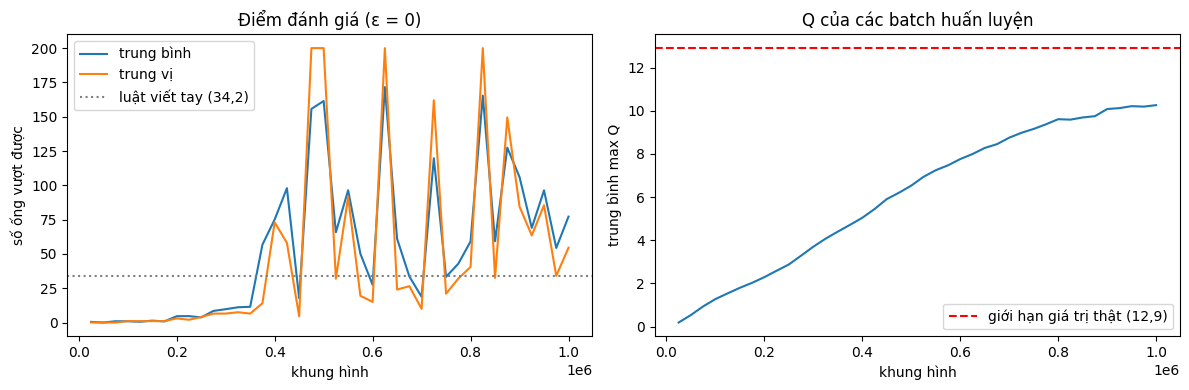

In [23]:
history = read_history(RUN_DIR)
if not history:
    raise FileNotFoundError(f"Chưa có lịch sử trong {RUN_DIR}. Hãy chạy mục 11 trước.")

frames = [r["frame"] for r in history]
fig, (ax_score, ax_q) = plt.subplots(1, 2, figsize=(12, 4))

ax_score.plot(frames, [r["eval"]["mean"] for r in history], label="trung bình")
ax_score.plot(frames, [r["eval"]["median"] for r in history], label="trung vị")
ax_score.axhline(34.2, color="gray", linestyle=":", label="luật viết tay (34,2)")
ax_score.set_xlabel("khung hình")
ax_score.set_ylabel("số ống vượt được")
ax_score.set_title("Điểm đánh giá (ε = 0)")
ax_score.legend()

ax_q.plot(frames, [r["mean_max_q"] for r in history])
ax_q.axhline(12.9, color="red", linestyle="--", label="giới hạn giá trị thật (12,9)")
ax_q.set_xlabel("khung hình")
ax_q.set_ylabel("trung bình max Q")
ax_q.set_title("Q của các batch huấn luyện")
ax_q.legend()

plt.tight_layout()
plt.show()

## 13. Đánh giá cuối

Cell này tự dựng agent mới và tải `best.weights.h5` từ Drive, nên chạy được độc lập với mục 11 (chỉ cần các mục 1 đến 9).

Agent chơi 100 ván với ε = 0, tức luôn chọn hành động có Q lớn nhất. Mỗi ván dừng ở 1.000 ống để agent giỏi không chơi mãi. Trường hợp xấu nhất (mọi ván đều chạm giới hạn) mất khoảng 18 phút trên máy cá nhân.

Báo cáo trung bình, trung vị, thấp nhất và cao nhất, vì điểm dao động mạnh giữa các ván. Mốc so sánh:

| Cách chơi | Điểm trung bình |
|---|---|
| Ngẫu nhiên, vỗ cánh ở một nửa số khung hình | 0 |
| Luật viết tay (mục 1.6 của `Problem_Definition.md`) | 34,2 |

Đã tải /content/drive/MyDrive/FlappyBird/dqn_run1/best.weights.h5
Trung bình 341.60 | trung vị 294 | thấp nhất 3 | cao nhất 1000
Số ván chạm giới hạn 1000: 2/100


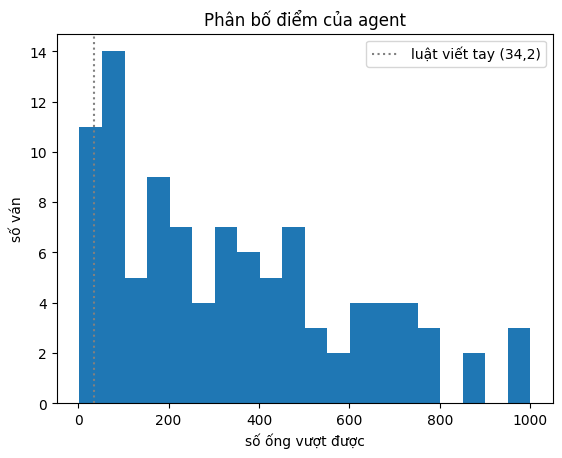

In [24]:
checkpoint_path = os.path.join(RUN_DIR, EVAL_CONFIG["checkpoint_name"])
if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(f"Không thấy {checkpoint_path}. Hãy chạy mục 11 trước.")

eval_agent = DQNAgent(OBS_DIM, N_ACTIONS, hidden_units=CONFIG["hidden_units"])
eval_agent.load(checkpoint_path)
print("Đã tải", checkpoint_path)

scores = play_episodes(eval_agent.greedy_action, EVAL_CONFIG["n_episodes"],
                       EVAL_CONFIG["eval_seed"], EVAL_CONFIG["score_limit"])
stats = summarize_scores(scores)
print(f"Trung bình {stats['mean']:.2f} | trung vị {stats['median']:.0f} | "
      f"thấp nhất {stats['min']} | cao nhất {stats['max']}")
print(f"Số ván chạm giới hạn {EVAL_CONFIG['score_limit']}: "
      f"{int(np.sum(scores >= EVAL_CONFIG['score_limit']))}/{len(scores)}")

plt.hist(scores, bins=20)
plt.axvline(34.2, color="gray", linestyle=":", label="luật viết tay (34,2)")
plt.xlabel("số ống vượt được")
plt.ylabel("số ván")
plt.title("Phân bố điểm của agent")
plt.legend()
plt.show()

## 14. Kiểm tra giá trị Q

Với γ = 0,99, một agent không bao giờ chết nhận tổng reward có chiết khấu khoảng 11,9 đến 12,9. Vì vậy:

- Q ở các trạng thái an toàn nên nằm quanh khoảng này.
- Trạng thái sát va chạm có Q thấp hơn, xuống tới khoảng −1.
- Không trạng thái nào có giá trị thật cao hơn 12,9. Q vượt rõ mức này là dấu hiệu đánh giá quá cao.

Cell dưới cho agent ở mục 13 chơi một ván (tối đa 50 ống), ghi lại mọi observation, rồi xem phân bố max Q trên các trạng thái đó.

1906 trạng thái | max Q: trung bình 8.16, thấp nhất 7.25, cao nhất 9.01
Tỷ lệ trạng thái có max Q > 12,9: 0.0%


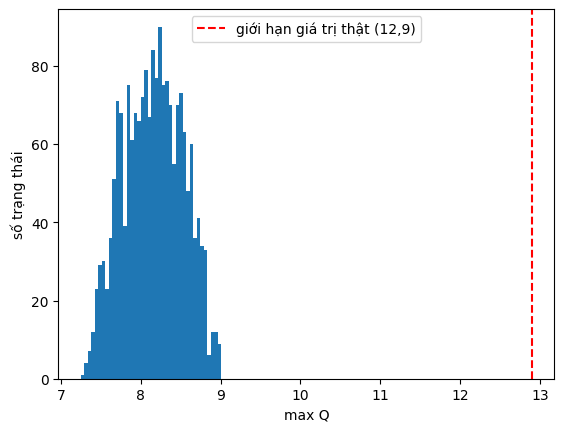

In [25]:
def collect_states(policy, seed, score_limit):
    env = FlappyEnv(score_limit=score_limit)
    states = []
    try:
        state = env.reset(seed=seed)
        episode_over = False
        while not episode_over:
            states.append(state)
            state, _, terminated, truncated, _ = env.step(policy(state))
            episode_over = terminated or truncated
    finally:
        env.close()
    return np.array(states)


visited = collect_states(eval_agent.greedy_action, EVAL_CONFIG["eval_seed"],
                         EVAL_CONFIG["q_check_score_limit"])
max_q = eval_agent.q_values(visited).max(axis=1)
print(f"{len(visited)} trạng thái | max Q: trung bình {max_q.mean():.2f}, "
      f"thấp nhất {max_q.min():.2f}, cao nhất {max_q.max():.2f}")
print(f"Tỷ lệ trạng thái có max Q > 12,9: {np.mean(max_q > 12.9):.1%}")

plt.hist(max_q, bins=40)
plt.axvline(12.9, color="red", linestyle="--", label="giới hạn giá trị thật (12,9)")
plt.xlabel("max Q")
plt.ylabel("số trạng thái")
plt.legend()
plt.show()

## 15. Xem agent chơi (video)

Colab không mở được cửa sổ `pygame`, nên thay vì chế độ `"human"`, môi trường chạy với `render_mode="rgb_array"`: mỗi khung hình được vẽ thành một ảnh 288 × 512. Các ảnh được ghép thành video MP4 ở 30 khung hình/giây (đúng tốc độ của trò chơi), lưu vào `agent_play.mp4` trên Drive và hiển thị ngay dưới cell.

Ván dừng ở 20 ống, tức khoảng 25 giây video. Cell dùng `imageio`, có sẵn trên Colab.

In [26]:
import imageio
from IPython.display import Video, display

video_frames = []
watch_score = 0
env = FlappyEnv(score_limit=EVAL_CONFIG["video_score_limit"], render_mode="rgb_array")
try:
    state = env.reset(seed=EVAL_CONFIG["eval_seed"])
    video_frames.append(env.render())
    episode_over = False
    while not episode_over:
        state, _, terminated, truncated, watch_score = env.step(eval_agent.greedy_action(state))
        video_frames.append(env.render())
        episode_over = terminated or truncated
finally:
    env.close()

video_path = os.path.join(RUN_DIR, "agent_play.mp4")
imageio.mimsave(video_path, video_frames, fps=30)
print(f"Số ống vượt được: {watch_score} | {len(video_frames)} khung hình | đã lưu {video_path}")
display(Video(video_path, embed=True, width=288))

Số ống vượt được: 20 | 777 khung hình | đã lưu /content/drive/MyDrive/FlappyBird/dqn_run1/agent_play.mp4
